# 1

dy/dx = y + 8y^2 - 9y^3
y(0)=1/2
t in [0,3]

Global error vs step size — Euler: slope = 1.026
Global error vs step size — Explicit trapezoid: slope = 2.065
Global error vs step size — RK4: slope = 4.085


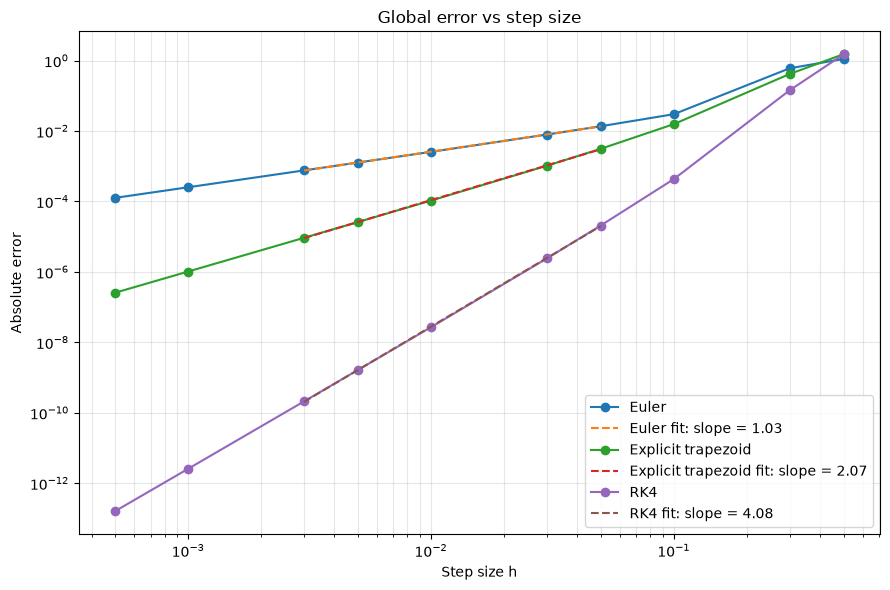

Local truncation error vs step size — Euler: slope = 1.997
Local truncation error vs step size — Explicit trapezoid: slope = 3.043
Local truncation error vs step size — RK4: slope = 5.034


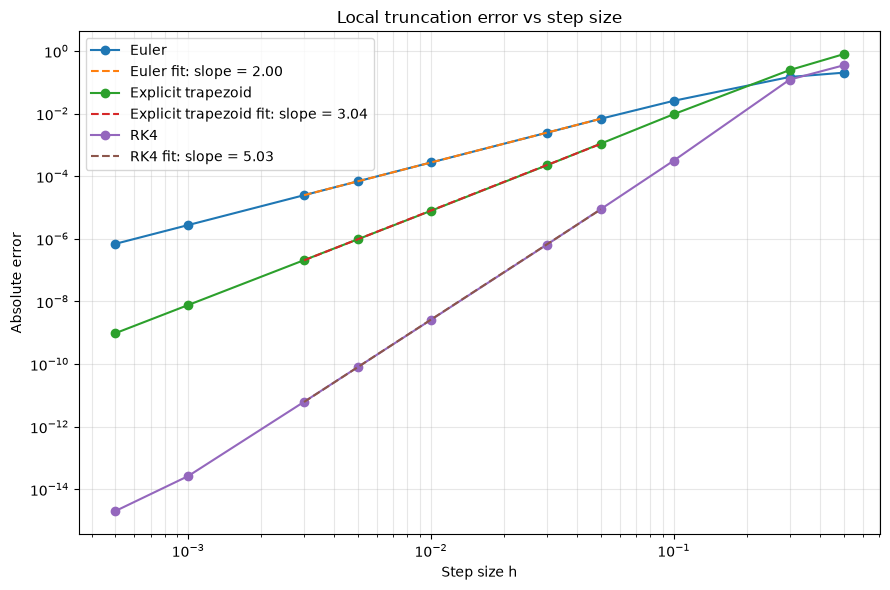

In [10]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq


x0, T = 0.0, 3.0
y0 = 0.5

steps = [0.5, 0.3, 0.1, 0.03, 0.05,
         0.01, 0.003, 0.005, 0.001, 0.0005]


def f(x, y):
    return y + 8*y**2 - 9*y**3

def exact_y(x):
    if x == 0:
        return y0

    def residual(y):
        return (
            10*np.log(y)
            - np.log(1-y)
            - 9*np.log(1+9*y)
            - 10*x
            + 9*np.log(11)
        )

    return brentq(
        residual, 0.5, 1 - 1e-14, xtol=1e-15, rtol=4*np.finfo(float).eps)


def euler_step(x, y, h):
    return y + h*f(x, y)


def trapezoid_step(x, y, h):
    k1 = f(x, y)
    k2 = f(x + h, y + h*k1)
    return y + h/2*(k1 + k2)


def rk4_step(x, y, h):
    k1 = f(x, y)
    k2 = f(x + h/2, y + h*k1/2)
    k3 = f(x + h/2, y + h*k2/2)
    k4 = f(x + h, y + h*k3)

    return y + h/6*(k1 + 2*k2 + 2*k3 + k4)


methods = {
    "Euler": euler_step,
    "Explicit trapezoid": trapezoid_step,
    "RK4": rk4_step,
}

global_errors = {name: [] for name in methods}
local_errors = {name: [] for name in methods}

for h in steps:
    N = round((T - x0)/h)
    x = np.linspace(x0, T, N + 1)

    y_exact = np.array([exact_y(xi) for xi in x])

    for name, step_method in methods.items():

        y_num = np.zeros(N + 1)
        y_num[0] = y0

        for i in range(N):
            y_num[i + 1] = step_method(x[i], y_num[i], h)

        global_error = np.max(np.abs(y_num - y_exact))
        global_errors[name].append(global_error)
        one_step_values = np.array([ step_method(x[i], y_exact[i], h) for i in range(N)])
        local_error = np.max(np.abs(one_step_values - y_exact[1:]))
        local_errors[name].append(local_error)



steps = np.array(steps)
order = np.argsort(steps)
h_sorted = steps[order]
fit_mask = (h_sorted >= 0.003) & (h_sorted <= 0.05)


def plot_errors(errors, title):
    plt.figure(figsize=(9, 6))
    for name, values in errors.items():
        values = np.array(values)[order]

        plt.loglog(h_sorted, values, "o-", label=name)
        slope, intercept = np.polyfit(np.log(h_sorted[fit_mask]), np.log(values[fit_mask]), 1)
        plt.loglog(h_sorted[fit_mask], np.exp(intercept) * h_sorted[fit_mask]**slope, "--", label=f"{name} fit: slope = {slope:.2f}")
        print(f"{title} — {name}: slope = {slope:.3f}")

    plt.xlabel("Step size h")
    plt.ylabel("Absolute error")
    plt.title(title)
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_errors(global_errors, "Global error vs step size")

plot_errors(local_errors, "Local truncation error vs step size")


# 2


Code two functions for a Backward Euler method using for the first one fixed point
iterations and Newton’s method for the second one.
Use this function to reproduce Figure 6.22 for Example 6.25 (see above), compare errors (local
and global) for Euler, Backward Euler (use Newton’s method subroutine of two coded before),
Trapezoid, and RK4 methods for steps h = 0.3, h = 0.15, h = 0.03, h = 0.01. Fixed point
iterations will fail for h = 0.3, explain why.

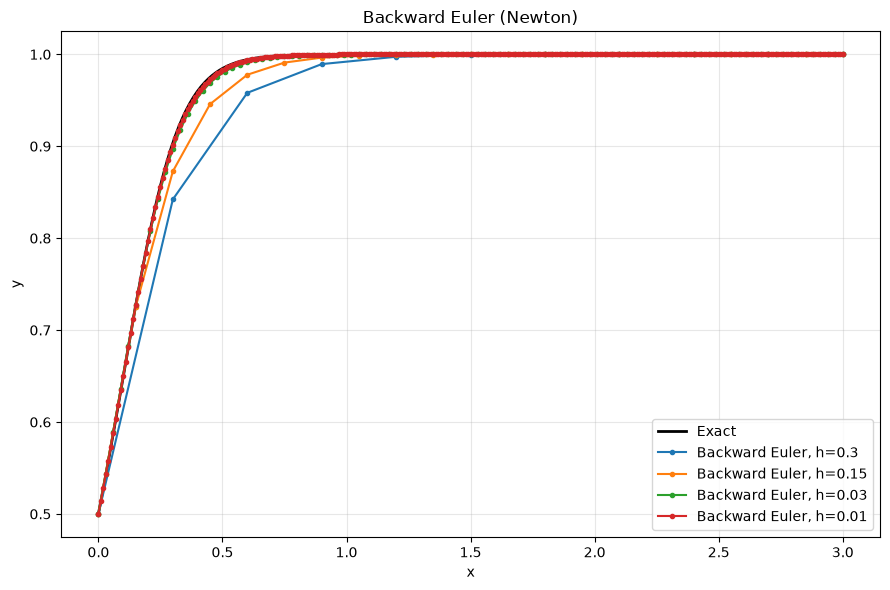

Fixed-point iteration did not converge
Newton solution of the first step: z* = 0.842148
|h * df/dy(z*)| = 1.402 > 1, so the iteration is not a contraction
Global error vs step size — Euler: slope = 1.482
Global error vs step size — Backward Euler (Newton): slope = 0.934
Global error vs step size — Explicit trapezoid: slope = 2.408
Global error vs step size — RK4: slope = 4.516


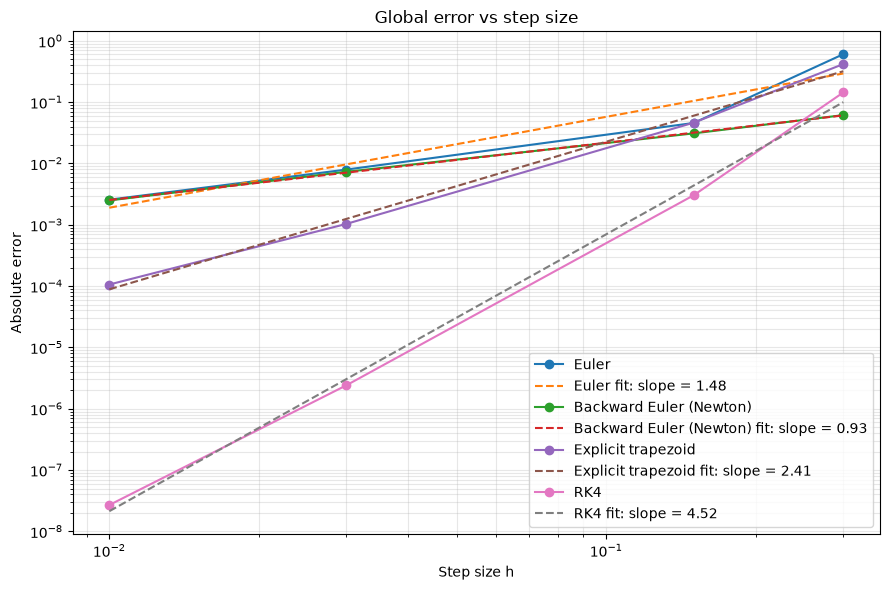

Local truncation error vs step size — Euler: slope = 1.852
Local truncation error vs step size — Backward Euler (Newton): slope = 1.626
Local truncation error vs step size — Explicit trapezoid: slope = 3.050
Local truncation error vs step size — RK4: slope = 5.182


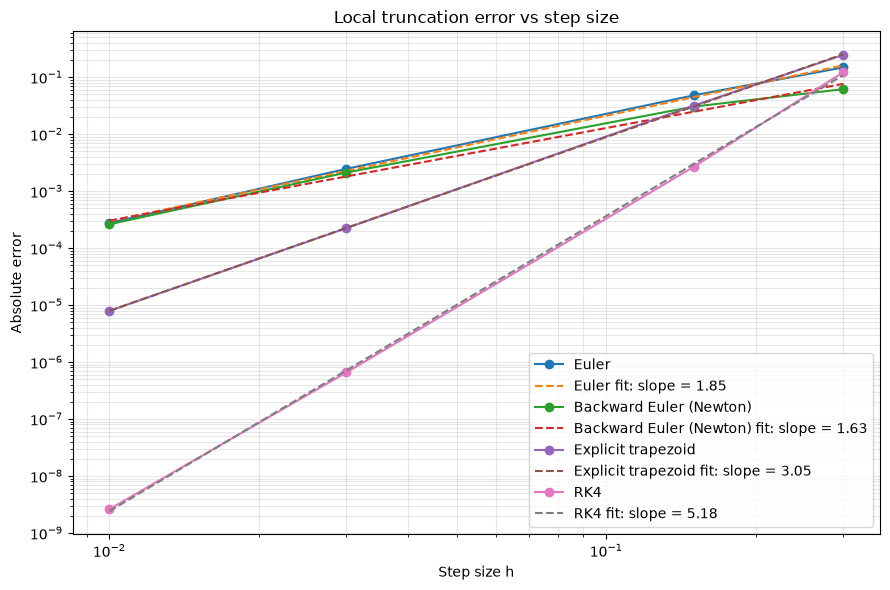

In [ ]:
def plot_errors(errors, title, h_sorted, order, fit_mask):
    plt.figure(figsize=(9, 6))
    for name, values in errors.items():
        values = np.array(values)[order]

        plt.loglog(h_sorted, values, "o-", label=name)
        slope, intercept = np.polyfit(np.log(h_sorted[fit_mask]), np.log(values[fit_mask]), 1)
        plt.loglog(h_sorted[fit_mask], np.exp(intercept) * h_sorted[fit_mask]**slope, "--", label=f"{name} fit: slope = {slope:.2f}")
        print(f"{title} — {name}: slope = {slope:.3f}")

    plt.xlabel("Step size h")
    plt.ylabel("Absolute error")
    plt.title(title)
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

def dfdy(x, y):
    return 1 + 16*y - 27*y**2


def backward_euler_fixed_point(x, y, h, tol=1e-12, max_iter=100):
    z = y

    for _ in range(max_iter):
        z_new = y + h * f(x + h, z)

        if abs(z_new - z) < tol:
            return z_new

        z = z_new

    raise RuntimeError("Fixed-point iteration did not converge")


def backward_euler_newton(x, y, h, tol=1e-12, max_iter=100):
    z = y + h * f(x, y)

    for _ in range(max_iter):
        F = z - y - h * f(x + h, z)
        dF = 1 - h * dfdy(x + h, z)

        if abs(F) < tol:
            return z

        z_new = z - F/dF

        if abs(z_new - z) < tol:
            if abs(z_new - y - h * f(x + h, z_new)) < 100 * tol:
                return z_new

        z = z_new
    raise RuntimeError("Newton's method did not converge")


def solve(step_method, h):
    N = round((T - x0) / h)
    x = np.linspace(x0, T, N + 1)
    y = np.empty(N + 1)
    y[0] = y0
    for i in range(N):
        y[i + 1] = step_method(x[i], y[i], h)
    return x, y


x_exact = np.linspace(x0, T, 400)
y_exact_plot = np.array([exact_y(xi) for xi in x_exact])

plt.figure(figsize=(9, 6))
plt.plot(x_exact, y_exact_plot, "k-", lw=2, label="Exact")
for h in [0.3, 0.15, 0.03, 0.01]:
    x, y = solve(backward_euler_newton, h)
    plt.plot(x, y, "o-", ms=3, label=f"Backward Euler, h={h}")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Backward Euler (Newton)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



h = 0.3
try:
    backward_euler_fixed_point(x0, y0, h)
    print(f"h = {h}: fixed point converged")
except RuntimeError as err:
    z_star = backward_euler_newton(x0, y0, h)
    contraction = abs(h * dfdy(x0 + h, z_star))
    print(err)
    print(f"Newton solution of the first step: z* = {z_star:.6f}")
    print(f"|h * df/dy(z*)| = {contraction:.3f} > 1, so the iteration is not a contraction")

steps = [0.3, 0.15, 0.03, 0.01]

methods = {
    "Euler": euler_step,
    "Backward Euler (Newton)": backward_euler_newton,
    "Explicit trapezoid": trapezoid_step,
    "RK4": rk4_step,
}

global_errors = {name: [] for name in methods}
local_errors = {name: [] for name in methods}

for h in steps:
    x, _ = solve(euler_step, h)
    y_exact = np.array([exact_y(xi) for xi in x])

    for name, step_method in methods.items():
        _, y_num = solve(step_method, h)

        global_errors[name].append(np.max(np.abs(y_num - y_exact)))

        one_step_values = np.array([
            step_method(x[i], y_exact[i], h) for i in range(len(x) - 1)
        ])
        local_errors[name].append(np.max(np.abs(one_step_values - y_exact[1:])))


steps = np.array(steps)
order = np.argsort(steps)
h_sorted = steps[order]
fit_mask = (h_sorted >= 0.003) & (h_sorted <= 0.05)

plot_errors(global_errors, "Global error vs step size",
            h_sorted, order, np.ones_like(h_sorted, dtype=bool))
plot_errors(local_errors, "Local truncation error vs step size",
            h_sorted, order, np.ones_like(h_sorted, dtype=bool))


Fixed-point iteration for one backward Euler step is

$$z_{k+1} = y_n + h f(x_n + h, z_k).$$

It converges only when this map is a contraction near the root, that is $|h \partial f/\partial y| < 1$.

For $f(y) = y + 8y^2 - 9y^3$ one has $\partial f/\partial y = 1 + 16y - 27y^2$. On the first step, $y_0 = 1/2$ and $h = 0.3$, Newton finds $z^* \approx 0.842$ and

$$|h \partial f/\partial y(z^*)| \approx 1.40 > 1.$$

The fixed point is repulsive, so the iteration diverges. Newton's method solves $F(z) = z - y_n - h f(x_n+h, z) = 0$ and does not need this restriction, so the same step converges.

# 3

f(0) = 1.0
f(9) = 6.639677199580735e-36
Exact max/min ratio = 1.5060973145850306e+35
log10(max/min) = 35.1778530341634
Maximum reconstruction error: 3.3306690738754696e-16
Maximum relative error: 2.1413187855655264e+19


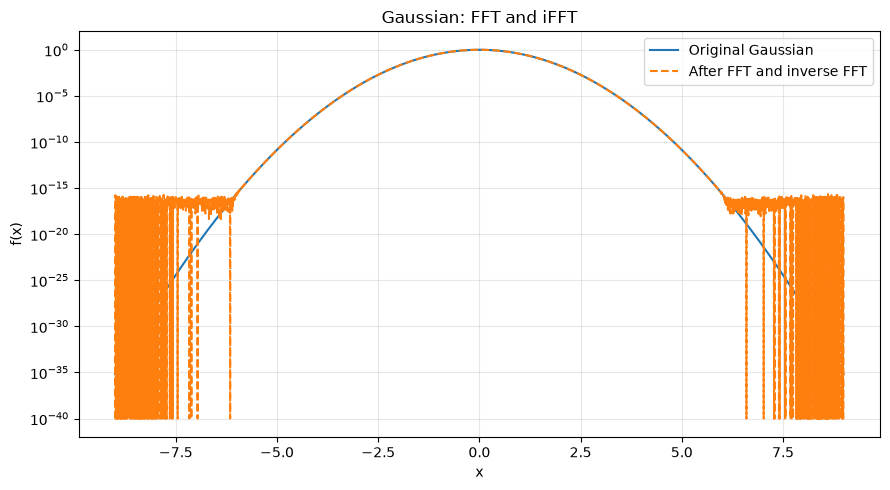

In [15]:

import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return np.exp(-x**2)


L = 9.0
N = 4096

x = np.linspace(-L, L, N, endpoint=False)
y = f(x)

y_hat = np.fft.fft(y)

y_rec = np.fft.ifft(y_hat).real

print("f(0) =", f(0))
print("f(9) =", f(9))
print("Exact max/min ratio =", np.exp(L**2))
print("log10(max/min) =", L**2 / np.log(10))


print("Maximum reconstruction error:", np.max(np.abs(y - y_rec)))
relative_error = np.abs(y_rec - y) / y

print("Maximum relative error:", np.max(relative_error))

plt.figure(figsize=(9, 5))

plt.semilogy(x, y, label="Original Gaussian")
plt.semilogy(x, np.maximum(np.abs(y_rec), 1e-40), "--",label="After FFT and inverse FFT")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Gaussian: FFT and iFFT")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()





     N            FFT        Forward        Central
    16   3.344977e-01   8.260145e-01   3.239611e-01
    32   1.054868e-03   5.221690e-01   2.052778e-01
    64   5.246082e-14   2.697090e-01   5.561221e-02
   128   1.466496e-15   1.359663e-01   1.419217e-02
   256   2.680860e-15   6.812319e-02   3.566468e-03
   512   7.715583e-15   3.407914e-02   8.927741e-04
  1024   1.426524e-14   1.704176e-02   2.232659e-04
  2048   3.420681e-14   8.521156e-03   5.582101e-05
  4096   7.144977e-14   4.260612e-03   1.395554e-05


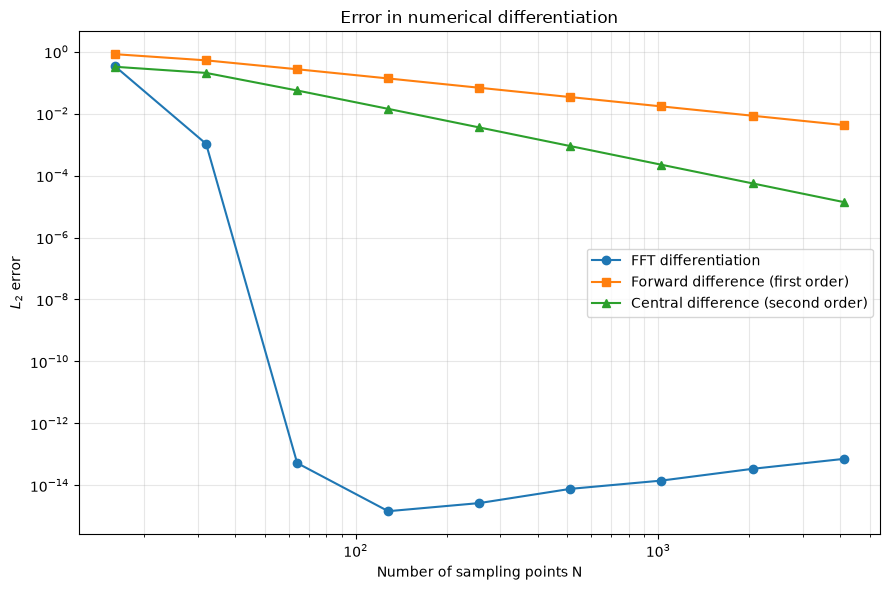

In [16]:

import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return np.exp(-x**2)

def df_exact(x):
    return -2 * x * np.exp(-x**2)


L = 9.0


def derivative_fft(y, h):
    N = len(y)
    k = 2 * np.pi * np.fft.fftfreq(N, d=h)
    y_hat = np.fft.fft(y)

    dy_hat = 1j * k * y_hat

    if N % 2 == 0:
        dy_hat[N // 2] = 0.0

    return np.fft.ifft(dy_hat).real


def derivative_forward(y, h):
    return (np.roll(y, -1) - y) / h


def derivative_central(y, h):
    return (np.roll(y, -1) - np.roll(y, 1)) / (2 * h)


def L2_error(dy_num, dy_true, h):
    return np.sqrt(h * np.sum((dy_num - dy_true)**2))


N_values = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096]

errors_fft = []
errors_forward = []
errors_central = []

for N in N_values:
    h = 2 * L / N
    x = np.linspace(-L, L, N, endpoint=False)

    y = f(x)
    dy_true = df_exact(x)

    dy_fft = derivative_fft(y, h)
    dy_forward = derivative_forward(y, h)
    dy_central = derivative_central(y, h)

    errors_fft.append(L2_error(dy_fft, dy_true, h))
    errors_forward.append(L2_error(dy_forward, dy_true, h))
    errors_central.append(L2_error(dy_central, dy_true, h))


print(f"{'N':>6} {'FFT':>14} {'Forward':>14} {'Central':>14}")
for N, e_fft, e_forward, e_central in zip(
        N_values, errors_fft, errors_forward, errors_central):
    print(f"{N:6d} {e_fft:14.6e} "
          f"{e_forward:14.6e} {e_central:14.6e}")

plt.figure(figsize=(9, 6))

plt.loglog(N_values, errors_fft, "o-",
           label="FFT differentiation")
plt.loglog(N_values, errors_forward, "s-",
           label="Forward difference (first order)")
plt.loglog(N_values, errors_central, "^-",
           label="Central difference (second order)")

plt.xlabel("Number of sampling points N")
plt.ylabel(r"$L_2$ error")
plt.title("Error in numerical differentiation")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# 5

First-order errors: [0.01135442 0.00291934 0.00077155 0.0004319  0.0002392  0.00012614
 0.00006472 0.00003281 0.00001658]
SS2 errors: [8.04082058e-03 2.01036057e-03 5.02596687e-04 1.25642759e-04
 3.13991688e-05 7.82648172e-06]
Global orders, first-order method: [1.95954222 1.91981142 0.83704322 0.85251638 0.92318462
 0.9627     0.9804     0.9844]
Global orders, SS2: [1.99988846 1.99998122 2.00007363 2.00053614 2.00429055]


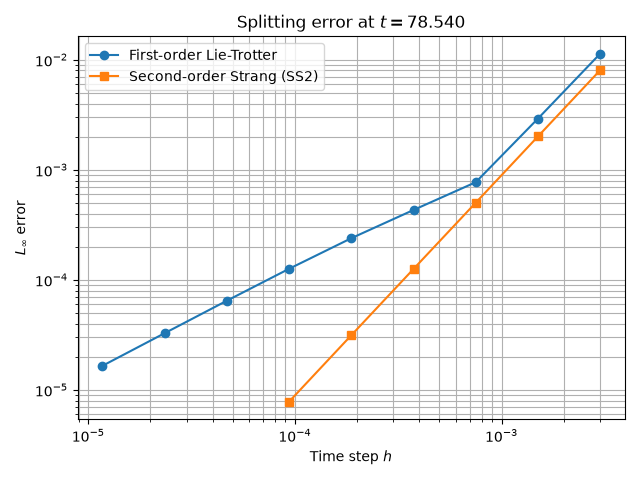

In [7]:

import numpy as np
import matplotlib.pyplot as plt


L = 25 * np.pi
N = 1024
x = np.linspace(-L, L, N, endpoint=False)
dx = 2 * L / N


k = 2 * np.pi * np.fft.fftfreq(N, d=dx)


lam = 2.0
v = 2.0
x0 = 0.0
phi0 = 0.0


T = 2 * L / v


def exact_solution(x, t):
    phase = 0.5 * v * x + (lam - v**2 / 4) * t + phi0
    d = (x - v * t - x0 + L) % (2 * L) - L      # this line must be present
    return np.sqrt(2 * lam) * np.exp(1j * phase) / np.cosh(np.sqrt(lam) * d)

                                   # not 0.37 * T


def linear_step(phi, dt):
    
    phi_hat = np.fft.fft(phi)
    phi_hat *= np.exp(-1j * k**2 * dt)
    return np.fft.ifft(phi_hat)


def nonlinear_step(phi, dt):
    
    return np.exp(1j * np.abs(phi)**2 * dt) * phi


def split_step_first_order(phi, dt):
    
    phi = nonlinear_step(phi, dt)
    phi = linear_step(phi, dt)
    return phi


def split_step_second_order(phi, dt):
    
    phi = linear_step(phi, dt / 2)
    phi = nonlinear_step(phi, dt)
    phi = linear_step(phi, dt / 2)
    return phi


T = 2 * L / v
T_err = T      

dt_values = []
errors_first = []
errors_second = []

dt_targets = [
    0.003,
    0.0015,
    0.00075,
    0.000375,
    0.0001875,
    0.00009375,
]

dt_first_only = [
    0.000046875,
    0.0000234375,
    0.00001171875,
]

for dt_target in dt_targets:
    n_steps = round(T_err / dt_target)
    dt = T_err / n_steps

    phi_first = exact_solution(x, 0.0)
    phi_second = phi_first.copy()

    for _ in range(n_steps):
        phi_first  = split_step_first_order(phi_first, dt)
        phi_second = split_step_second_order(phi_second, dt)

    phi_exact = exact_solution(x, T_err)

    dt_values.append(dt)
    errors_first.append(np.max(np.abs(phi_first - phi_exact)))
    errors_second.append(np.max(np.abs(phi_second - phi_exact)))

for dt_target in dt_first_only:
    n_steps = round(T_err / dt_target)
    dt = T_err / n_steps

    phi_first = exact_solution(x, 0.0)
    for _ in range(n_steps):
        phi_first = split_step_first_order(phi_first, dt)

    phi_exact = exact_solution(x, T_err)
    dt_values.append(dt)
    errors_first.append(np.max(np.abs(phi_first - phi_exact)))

dt_values = np.array(dt_values)
errors_first = np.array(errors_first)
errors_second = np.array(errors_second)
dt_second = dt_values[:len(errors_second)]

p_first = np.log(errors_first[:-1] / errors_first[1:]) / np.log(
    dt_values[:-1] / dt_values[1:]
)
p_second = np.log(errors_second[:-1] / errors_second[1:]) / np.log(
    dt_second[:-1] / dt_second[1:]
)

print("First-order errors:", errors_first)
print("SS2 errors:", errors_second)
print("Global orders, first-order method:", p_first)
print("Global orders, SS2:", p_second)


plt.loglog(dt_values, errors_first, "o-", label="First-order Lie-Trotter")
plt.loglog(dt_second, errors_second, "s-", label="Second-order Strang (SS2)")

plt.xlabel("Time step $h$")
plt.ylabel(r"$L_\infty$ error")
plt.title(f"Splitting error at $t={T_err:.3f}$")
plt.grid(True, which="both")
plt.legend()
plt.show()

# 6

dt = 7.999574e-03, relative error = 1.939839e-02, mean HIM iterations = 6.00, max HIM iterations = 6
dt = 3.999991e-03, relative error = 4.851264e-03, mean HIM iterations = 5.00, max HIM iterations = 5
dt = 1.999995e-03, relative error = 1.212839e-03, mean HIM iterations = 4.75, max HIM iterations = 5
dt = 9.999977e-04, relative error = 3.032174e-04, mean HIM iterations = 4.00, max HIM iterations = 4

Observed convergence orders:
dt: 7.9996e-03 -> 3.9990e-03, p = 2.0000
dt: 3.9990e-03 -> 1.9995e-03, p = 2.0000
dt: 1.9995e-03 -> 9.9998e-04, p = 2.0000


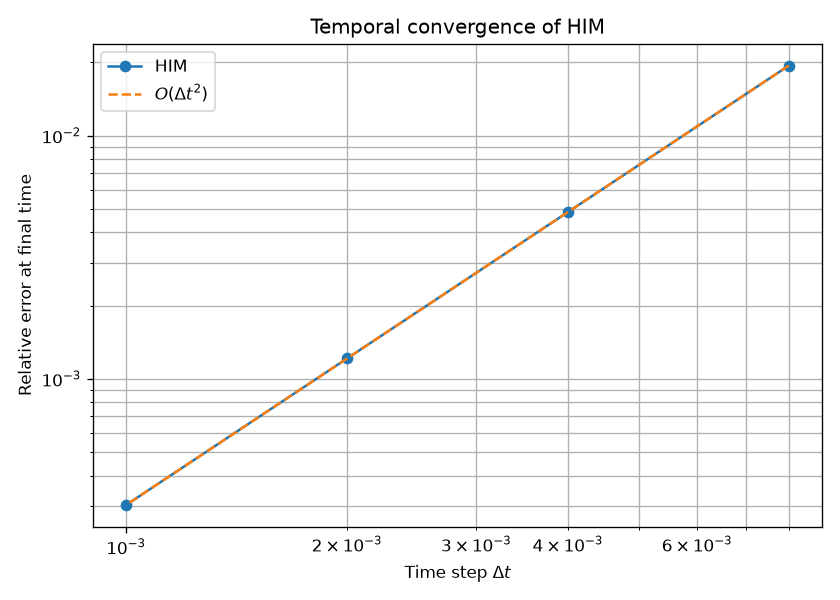

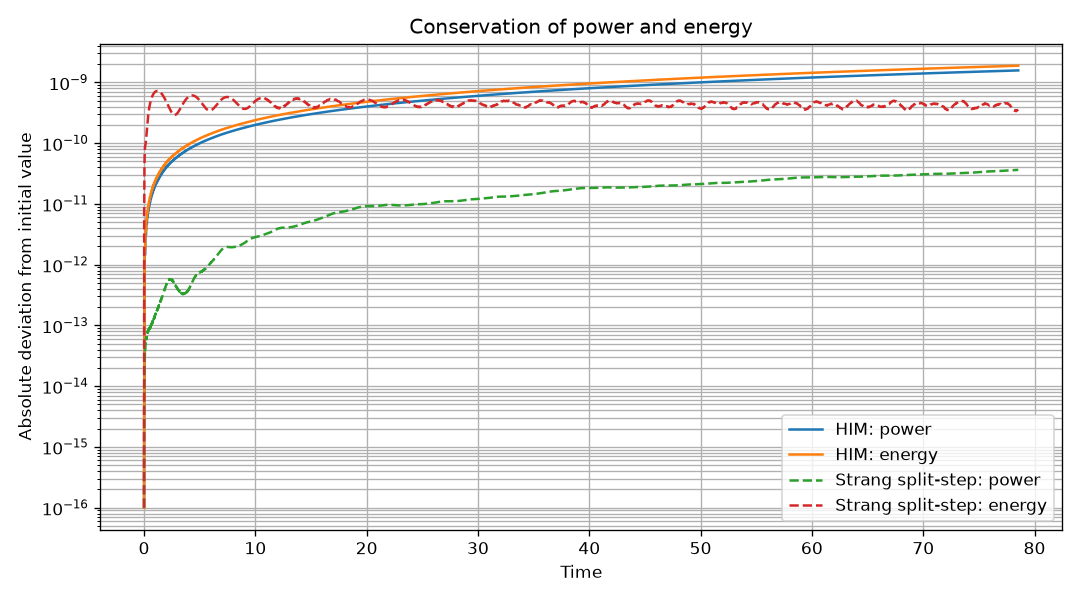

Mean HIM iterations: 4.75
Maximum HIM iterations: 5
Final HIM power deviation: 1.577742e-09
Final HIM energy deviation: 1.886411e-09
Final split-step power deviation: 3.640466e-11
Final split-step energy deviation: 3.561735e-10


In [11]:
import numpy as np
import matplotlib.pyplot as plt



L = 25 * np.pi
N = 1024

v = 2.0
lam = 2.0
x0 = 0.0
phi0 = 0.0

T = 2 * L / v

x = np.linspace(-L, L, N, endpoint=False)
dx = 2 * L / N


k = 2 * np.pi * np.fft.fftfreq(N, d=dx)


def exact_solution(t):

    d = (x - v * t - x0 + L) % (2 * L) - L

    phase = 0.5 * v * x + (lam - v**2 / 4) * t + phi0

    return (
        np.sqrt(2 * lam)
        * np.exp(1j * phase)
        / np.cosh(np.sqrt(lam) * d)
    )


def initial_condition():
    return exact_solution(0.0)

def power(phi):
    return dx * np.sum(np.abs(phi)**2)


def energy(phi):
    
    phi_x = np.fft.ifft(1j * k * np.fft.fft(phi))

    density = np.abs(phi_x)**2 - 0.5 * np.abs(phi)**4

    return dx * np.sum(density).real


def him_step(phi_n, dt, tol=1e-11, max_iter=30):

    dt_max = 2.0 / (
        np.sqrt(3.0) * np.max(np.abs(phi_n)**2)
    )

    if dt >= dt_max:
        raise ValueError(
            f"dt={dt:.4e} violates the HIM condition "
            f"dt < {dt_max:.4e}"
        )

    phi_hat_n = np.fft.fft(phi_n)

    
    denominator = 1.0 + 0.5j * k**2 * dt

    linear_factor = (
        (1.0 - 0.5j * k**2 * dt) / denominator
    )

    nonlinear_factor = 1j * dt / (4.0 * denominator)

    
    phi_xx = np.fft.ifft(-(k**2) * phi_hat_n)
    phi_iter = phi_n + 1j * dt * (phi_xx + np.abs(phi_n)**2 * phi_n)

    for iteration in range(1, max_iter + 1):

        nonlinear_term = (
            (phi_iter + phi_n)
            * (np.abs(phi_iter)**2 + np.abs(phi_n)**2)
        )

        phi_hat_next = (
            linear_factor * phi_hat_n
            + nonlinear_factor * np.fft.fft(nonlinear_term)
        )

        phi_next = np.fft.ifft(phi_hat_next)

        
        numerator = np.max(np.abs(phi_next - phi_iter))
        denominator_error = np.max(np.abs(phi_next))

        rel_error = numerator / max(
            denominator_error, np.finfo(float).tiny
        )

        if rel_error <= tol:
            return phi_next, iteration, rel_error

        phi_iter = phi_next

    raise RuntimeError(
        f"HIM did not converge in {max_iter} iterations; "
        f"last relative error = {rel_error:.3e}"
    )


def solve_him(dt_target, store_invariants=False):
    n_steps = int(np.ceil(T / dt_target))
    dt = T / n_steps

    phi = initial_condition()

    if store_invariants:
        times = [0.0]
        powers = [power(phi)]
        energies = [energy(phi)]

    iteration_counts = []

    for n in range(n_steps):
        phi, n_iter, rel_error = him_step(phi, dt)
        iteration_counts.append(n_iter)

        if store_invariants:
            times.append((n + 1) * dt)
            powers.append(power(phi))
            energies.append(energy(phi))

    if store_invariants:
        return (
            phi, dt, np.array(times),
            np.array(powers), np.array(energies),
            np.array(iteration_counts)
        )

    return phi, dt, np.array(iteration_counts)


def solve_split_step(dt_target):
    n_steps = int(np.ceil(T / dt_target))
    dt = T / n_steps

    phi = initial_condition()


    linear_half = np.exp(-1j * k**2 * dt / 2)

    
    for _ in range(n_steps):
        phi = np.fft.ifft(
            linear_half * np.fft.fft(phi)
        )

        
        phi = phi * np.exp(1j * np.abs(phi)**2 * dt)

        
        phi = np.fft.ifft(
            linear_half * np.fft.fft(phi)
        )

    return phi, dt


dt_targets = [0.008, 0.004, 0.002, 0.001]

errors = []
actual_dts = []
mean_iterations = []

for dt_target in dt_targets:
    phi_num, dt, iteration_counts = solve_him(dt_target)

    phi_exact = exact_solution(T)

    error = (
        np.max(np.abs(phi_num - phi_exact))
        / np.max(np.abs(phi_exact))
    )

    actual_dts.append(dt)
    errors.append(error)
    mean_iterations.append(np.mean(iteration_counts))

    print(
        f"dt = {dt:.6e}, "
        f"relative error = {error:.6e}, "
        f"mean HIM iterations = {np.mean(iteration_counts):.2f}, "
        f"max HIM iterations = {np.max(iteration_counts)}"
    )

actual_dts = np.array(actual_dts)
errors = np.array(errors)


orders = (
    np.log(errors[:-1] / errors[1:])
    / np.log(actual_dts[:-1] / actual_dts[1:])
)

print("\nObserved convergence orders:")
for i, p in enumerate(orders):
    print(
        f"dt: {actual_dts[i]:.4e} -> {actual_dts[i+1]:.4e}, "
        f"p = {p:.4f}"
    )

plt.figure(figsize=(7, 5))
plt.loglog(actual_dts, errors, "o-", label="HIM")


reference = errors[0] * (actual_dts / actual_dts[0])**2
plt.loglog(actual_dts, reference, "--", label=r"$O(\Delta t^2)$")

plt.xlabel(r"Time step $\Delta t$")
plt.ylabel("Relative error at final time")
plt.title("Temporal convergence of HIM")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()


dt_conservation = 0.002

(
    phi_him, dt_him, times,
    powers_him, energies_him, iteration_counts
) = solve_him(dt_conservation, store_invariants=True)

phi_ss, dt_ss = solve_split_step(dt_conservation)

n_steps = len(times) - 1
powers_ss = np.empty(n_steps + 1)
energies_ss = np.empty(n_steps + 1)

phi = initial_condition()
powers_ss[0] = power(phi)
energies_ss[0] = energy(phi)

linear_half = np.exp(-1j * k**2 * dt_him / 2)

for n in range(n_steps):
    phi = np.fft.ifft(linear_half * np.fft.fft(phi))
    phi = phi * np.exp(1j * np.abs(phi)**2 * dt_him)
    phi = np.fft.ifft(linear_half * np.fft.fft(phi))

    powers_ss[n + 1] = power(phi)
    energies_ss[n + 1] = energy(phi)


delta_power_him = np.abs(powers_him - powers_him[0])
delta_energy_him = np.abs(energies_him - energies_him[0])

delta_power_ss = np.abs(powers_ss - powers_ss[0])
delta_energy_ss = np.abs(energies_ss - energies_ss[0])

plt.figure(figsize=(9, 5))

plt.semilogy(
    times, np.maximum(delta_power_him, 1e-16),
    label="HIM: power"
)
plt.semilogy(
    times, np.maximum(delta_energy_him, 1e-16),
    label="HIM: energy"
)
plt.semilogy(
    times, np.maximum(delta_power_ss, 1e-16),
    "--", label="Strang split-step: power"
)
plt.semilogy(
    times, np.maximum(delta_energy_ss, 1e-16),
    "--", label="Strang split-step: energy"
)

plt.xlabel("Time")
plt.ylabel("Absolute deviation from initial value")
plt.title("Conservation of power and energy")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Mean HIM iterations: {np.mean(iteration_counts):.2f}")
print(f"Maximum HIM iterations: {np.max(iteration_counts)}")
print(f"Final HIM power deviation: {delta_power_him[-1]:.6e}")
print(f"Final HIM energy deviation: {delta_energy_him[-1]:.6e}")
print(f"Final split-step power deviation: {delta_power_ss[-1]:.6e}")
print(f"Final split-step energy deviation: {delta_energy_ss[-1]:.6e}")